In [ ]:
# conda env : plot_python
import pandas as pd
import seaborn as sns
import os
import glob
import time
import tqdm
import numpy as np
import pybedtools

# Plotting
from adjustText import adjust_text
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

# saving folder
figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/DMR_inspection/"
os.makedirs(figureDir, exist_ok=True)

# change working directory to the data directory

mode="dss_using_123_pairing_chrX_balance"
dr=f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/05.{mode}"
os.chdir(dr)

In [2]:
color_palette = {"Maternal" : "#e78080" ,
                 "Paternal" : "#8080b2" }
color_palette = {
    "Maternal": "#e78080",
    "Paternal": "#5757A6"
}

color_diff_dmr = {"strong" : '#2C3E8F',
                  "moderate" : '#5B8CC9',
                  "missing" : '#D3D3D3'
                 }

color_palette_category = {'strong Maternal' : '#FF0000',
                          'Moderate Maternal' : '#e78080',
                          "Moderate Paternal" : '#8484fc',
                            "Strong Paternal" : "#0000FF" }

In [3]:
p = "1e3"

## Read data

In [4]:
sex = pd.read_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/sex.trio.tsv", header = None, sep="\t", names = ['sample','sex'])
sex.head(2)

sex_male = sex.loc[sex['sex'] == 'Male',"sample"].tolist()
sex_male[1:10]

['HG005',
 'HG00609',
 'HG00621',
 'HG00642',
 'HG00658',
 'HG00673',
 'HG00706',
 'HG00738',
 'HG01074']

In [5]:
fai = pd.read_csv("/weka/scratch/jhu/aphill27/references/chm13/chm13v2.0.fa.fai", header= None, sep="\t", names=['chr', 'length'], usecols=[0,1])
fai = fai[~fai['chr'].str.contains("chrY|chrM")]
fai.head(2)

,chr,length
0,chr1,248387328
1,chr2,242696752


In [7]:
dmrs = glob.glob(f"dmrs.N05_filt.chr*.{p}.*csv")

# print(dmrs)
dmr = pd.DataFrame()
for d in tqdm.tqdm(dmrs):
    # print(d)
    dmr = pd.concat([dmr, pd.read_csv(d, sep="\t", header=0)])

print(dmr.shape)
dmr['chr']      = pd.Categorical(dmr['chr'], ordered = True, categories=[f"chr{i}" for i in list(range(1,23)) + ["X"]])
dmr['areaStat'] = dmr['areaStat']*-1
dmr['hap']      = dmr['areaStat'].apply(lambda x: 'Maternal' if x > 0 else 'Paternal')
dmr['strand']   = dmr['areaStat'].apply(lambda x: '+' if x > 0 else '-')

dmr['dmr_id']   = "." 
dmr             = dmr[['chr', 'start', 'end', 'dmr_id', 'areaStat', 'strand' ,'nCG', 'hap']]


dmr = dmr.sort_values(by = ['chr','start'])
dmr = dmr.reset_index(drop=True)
dmr.head(2)

100%|██████████| 23/23 [00:00<00:00, 810.70it/s]

(1507, 6)


,chr,start,end,dmr_id,areaStat,strand,nCG,hap
0,chr1,2140270,2140331,.,21.348505,+,4,Maternal
1,chr1,5236010,5236161,.,71.528896,+,21,Maternal


In [79]:
import pandas as pd

def merge_dmrs_no_overlap(dmr, max_gap=1000):
    df = dmr.sort_values(
        ["chr", "start", "end"]
    ).reset_index(drop=True)

    merged = []
    current = None

    def save_current():
        if current is not None:
            merged.append(current.copy())

    for row in df.itertuples(index=False):
        row = row._asdict()

        if current is None:
            current = row.copy()
            continue

        same_group = (
            row["chr"] == current["chr"]
            and row["strand"] == current["strand"]
            and row["hap"] == current["hap"]
        )

        close_enough = row["start"] - current["end"] <= max_gap

        if same_group and close_enough:
            current["end"] = max(current["end"], row["end"])
            current["nCG"] += row["nCG"]
            current["areaStat"] += row["areaStat"]
        else:
            save_current()
            current = row.copy()

    save_current()

    return pd.DataFrame(merged)

dmr_merged_df = merge_dmrs_no_overlap(dmr)

dmr_merged_df = dmr_merged_df[['chr','start','end','areaStat','nCG','strand']]
dmr_merged_df.to_csv(f"dmrs.N05_filt.all_chr.{p}.mrg.bed", sep = '\t', header=None, index = False)
# dmr_merged_df.to_csv("/path/to/project/pooch/pooch_data/PAR/dss_new/dmrs.N05_filt.all_chr.1e3.mrg.bed", sep = '\t', header=None, index = False)

dmr_merged_df.head(2)

,chr,start,end,areaStat,nCG,strand
0,chr1,2140270,2140331,21.348505,4,+
1,chr1,5236010,5236161,71.528896,21,+


In [15]:
diff_methyl = (
    "/path/to/project/pooch/pooch_data/07.models_using_DSS_insideCV/all_chr.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.bed"
    # "/path/to/project/pooch/pooch_data/PAR/pooch_input/chrX.missingrate_5.createDiffDatasetFromMethylDataset.flipped.mean.out"
)

# Load methylation bedGraph
diff_methyl = pybedtools.BedTool(diff_methyl)

# Convert DMR DataFrame to BEDTool
dmr_bed = pybedtools.BedTool.from_dataframe(dmr_merged_df)

# Intersect DMRs with methylation intervals
# intersected = dmr_bed.intersect(diff_methyl, wa=True, wb=True, loj=True)
intersected = dmr_bed.intersect(diff_methyl, wa=True, wb=True)

# Convert intersection to DataFrame with column names
intersected_df = intersected.to_dataframe(names=[
    "chr", "start", "end", "nCG", "areaStat", "hap",
    "chr2", "start2", "end2", "diff_methyl"
])

# Ensure numeric values
intersected_df["diff_methyl"] = pd.to_numeric(
    intersected_df["diff_methyl"], errors="coerce"
)
intersected_df.reset_index(drop=False, inplace=True)
intersected_df.columns = ['index','chr','start','end','areaStat','nCG',"strand",'chr2','start2','end2','diff_methyl']
# intersected_df.columns = ['chr','start','end','name','areaStat','strand','nCG','hap','chr2','start2','end2','diff_methyl']
# intersected_df.head(2)

# Average methylation difference per DMR
results = (
    intersected_df
    .groupby(["chr", "start", "end",'strand',"nCG", "areaStat"], as_index=False)
    .agg(diff_methyl_mean=("diff_methyl", "mean"))
)

# results.to_csv("dmr_average_diff_methyl.bed", sep="\t", index=False)
print(results.head())

    chr     start       end strand  nCG    areaStat  diff_methyl_mean
0  chr1   2140270   2140331      +    4   21.348505          0.102170
1  chr1   5236010   5236161      +   21   71.528896          0.060872
2  chr1   7357760   7358617      +   33  207.969889          0.147105
3  chr1   9487018   9487072      +    4   16.214247          0.080477
4  chr1  32328963  32329318      +   20  180.408517          0.227657


### DMR Burden

In [16]:
dmr = results.copy()

In [17]:
dmr['burden']           = abs(dmr['diff_methyl_mean'] * dmr['nCG'])
dmr['abs_areaStat']     = dmr['areaStat'].abs()
dmr['abs_diff.Methy']   = dmr['diff_methyl_mean'].abs()
dmr['hap']              = dmr['areaStat'].apply(lambda x: 'Maternal' if x > 0 else 'Paternal')
dmr['length']           = dmr['end'] - dmr['start']
# dmr['hap']              = pd.Categorical(dmr['hap'], ordered = True, categories = ["Maternal","Paternal"])
# dmr['chr']              = pd.Categorical(dmr['chr'], ordered = True, categories=[f"chr{i}" for i in list(range(1,23)) + ["X"]])

In [18]:
color_palette_category = {'strong Maternal' : '#FF0000',
                          'Moderate Maternal' : '#e78080',
                          "Moderate Paternal" : '#8484fc',
                            "Strong Paternal" : "#0000FF" }

dmr['rgb'] = ""
dmr.loc[(dmr['abs_diff.Methy'] >= 0.15) & (dmr['hap'] == "Maternal"), 'rgb'] = "#FF0000"
dmr.loc[(dmr['abs_diff.Methy'] >= 0.15) & (dmr['hap'] == "Paternal"), 'rgb'] = "#0000FF"
dmr.loc[(dmr['abs_diff.Methy'] < 0.15) & (dmr['hap'] == "Maternal"), 'rgb'] = "#e78080"
dmr.loc[(dmr['abs_diff.Methy'] < 0.15) & (dmr['hap'] == "Paternal"), 'rgb'] = "#8484fc"
dmr['empty'] = "."
dmr.head(2)

,chr,start,end,strand,nCG,areaStat,diff_methyl_mean,burden,abs_areaStat,abs_diff.Methy,hap,length,rgb,empty
0,chr1,2140270,2140331,+,4,21.348505,0.102170,0.408679,21.348505,0.102170,Maternal,61,#e78080,.
1,chr1,5236010,5236161,+,21,71.528896,0.060872,1.278310,71.528896,0.060872,Maternal,151,#e78080,.


In [19]:
dmr.shape

(880, 14)

In [20]:
# dmr[['chr','start','end','hap','abs_diff.Methy','empty','start','end','rgb']].to_csv("/path/to/project/pooch/pooch_data/05.dss_using_123_pairing/dmrs.N05_filt.all_chr.1e3.mrg.forPlotting.bed",sep='\t',header = False, index=False)
dmr[['chr','start','end','hap','abs_diff.Methy','empty','start','end','rgb']].to_csv(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/05.dss_using_123_pairing_chrX_balance/dmrs.N05_filt.all_chr.{p}.mrg.forPlotting.bed",sep='\t',header = False, index=False)

In [21]:
dmr.to_csv(f"dmrs.N05_filt.all_chr.{p}.mrg.bed",sep='\t',header = True, index=False)

In [22]:
dmr.head(2)

,chr,start,end,strand,nCG,areaStat,diff_methyl_mean,burden,abs_areaStat,abs_diff.Methy,hap,length,rgb,empty
0,chr1,2140270,2140331,+,4,21.348505,0.102170,0.408679,21.348505,0.102170,Maternal,61,#e78080,.
1,chr1,5236010,5236161,+,21,71.528896,0.060872,1.278310,71.528896,0.060872,Maternal,151,#e78080,.


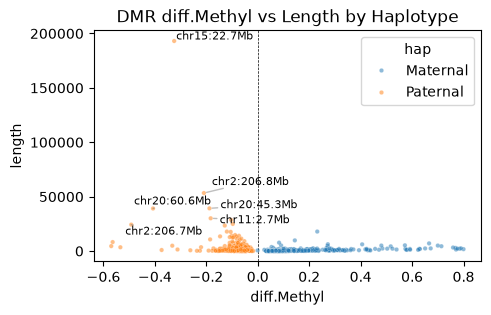

In [23]:
plt.figure(figsize=(5,3))

sns.scatterplot(data=dmr, x='diff_methyl_mean', y='length', hue='hap', alpha=0.5, s=10)
plt.axvline(0, color='black', linestyle='--', lw=0.5, zorder=-100)
plt.xlabel('diff.Methyl')
plt.ylabel('length')
plt.title('DMR diff.Methyl vs Length by Haplotype')

highlight_df = dmr.loc[(dmr['abs_diff.Methy'] > 0.15) & (dmr['length'] > 20000)]
highlight_df['name'] = highlight_df['chr'].astype(str) + ":" + (highlight_df['start'] / 1e6).round(1).astype(str) + "Mb"
# Add labels with automatic overlap avoidance
texts = []
for index, row in highlight_df.iterrows():
    text = plt.text(row['diff_methyl_mean'], row['length'], row['name'], fontsize=8)
    texts.append(text)

adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=1, alpha=0.5))

plt.savefig(os.path.join(figureDir, "scatter_dmr_diff_length_by_hap.p{p}.pdf"), bbox_inches='tight')
plt.show()

/tmp/ipykernel_322382/3387074600.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Mann-Whitney U test stats and p-value: 56900.0 3.83e-26


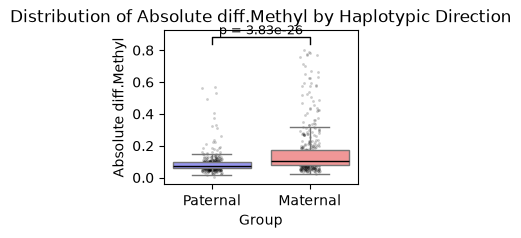

In [24]:
box_df = pd.DataFrame({
    'abs_diff': pd.concat([dmr.loc[dmr['diff_methyl_mean'] < 0, 'diff_methyl_mean'].abs(),
                           dmr.loc[dmr['diff_methyl_mean'] > 0, 'diff_methyl_mean'].abs()]),
    'Group': ['Paternal'] * (dmr['diff_methyl_mean'] < 0).sum() + ['Maternal'] * (dmr['diff_methyl_mean'] > 0).sum()
})

from scipy.stats import mannwhitneyu

plt.figure(figsize=(2.5,2))
# sns.swarmplot(data=box_df, x='Group', y='abs_diff', size=2, alpha=0.5)

# Draw jitter points first and keep them behind the box
sns.stripplot(
    data=box_df, x='Group', y='abs_diff',
    color='black', size=2, alpha=0.2, jitter=True,
    zorder=1
)

# Draw boxplot on top
sns.boxplot(
    data=box_df, x='Group', y='abs_diff',
    showcaps=True, showfliers=False,
    palette={'Paternal': '#8888FF', 'Maternal': '#FF8888'},
    boxprops=dict(zorder=3),
    whiskerprops=dict(zorder=3),
    capprops=dict(zorder=3),
    medianprops=dict(zorder=4, color='black')
)

# Wilcoxon rank-sum test
stat, pval = mannwhitneyu(
    box_df.loc[box_df['Group'] == 'Paternal', 'abs_diff'],
    box_df.loc[box_df['Group'] == 'Maternal', 'abs_diff'],
    alternative='two-sided'
)

print(f'Mann-Whitney U test stats and p-value: {stat} {pval:.2e}')
y_max = box_df['abs_diff'].max()
h = y_max * 0.05
plt.plot([0, 0, 1, 1], [y_max + h, y_max + 2*h, y_max + 2*h, y_max + h], lw=1, color='black')
plt.text(0.5, y_max + 2.5*h, f'p = {pval:.2e}', ha='center', fontsize=9)

plt.ylabel('Absolute diff.Methyl')
plt.title('Distribution of Absolute diff.Methyl by Haplotypic Direction')
plt.savefig(os.path.join(figureDir, "boxplot_diff_methyl_by_hap.p{p}.pdf"), bbox_inches='tight')
plt.show()

/tmp/ipykernel_322382/131872768.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


Paternal mean : 0.08746123769784998
Maternal mean : 0.1608787571035898
Paternal median : 0.07563403491035373
Maternal median : 0.10690579632972222
Mann-Whitney U test stats and p-value: 56900.0 3.83e-26


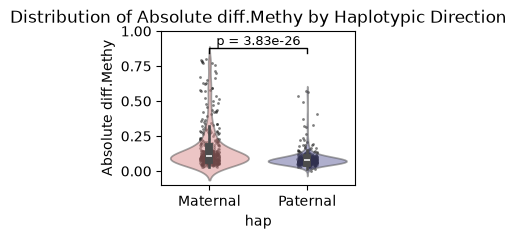

In [25]:
box_df['hap'] = pd.Categorical(box_df['Group'], ordered=True, categories = ['Maternal',"Paternal"])
from scipy.stats import mannwhitneyu

plt.figure(figsize=(2.5,2))
# sns.swarmplot(data=box_df, x='Group', y='abs_diff', size=2, alpha=0.5)

# Draw jitter points first and keep them behind the box


# Draw boxplot on top
sns.violinplot(
    data=box_df, x='hap', y='abs_diff',
    #showcaps=True, showfliers=False,
    palette=color_palette,
    #boxprops=dict(zorder=3),
    #whiskerprops=dict(zorder=3),
    #capprops=dict(zorder=3),
    #?medianprops=dict(zorder=4, color='black')
    alpha = 0.5
)
sns.stripplot(
    data=box_df, x='hap', y='abs_diff',
    color='black', size=2, alpha=0.5, jitter=True,
    zorder =-1
)
# Wilcoxon rank-sum test
stat, pval = mannwhitneyu(
    box_df.loc[box_df['hap'] == 'Paternal', 'abs_diff'],
    box_df.loc[box_df['hap'] == 'Maternal', 'abs_diff'],
    alternative='two-sided'
)
print(f"Paternal mean : {box_df.loc[box_df['hap'] == 'Paternal', 'abs_diff'].mean()}")
print(f"Maternal mean : {box_df.loc[box_df['hap'] == 'Maternal', 'abs_diff'].mean()}")

print(f"Paternal median : {box_df.loc[box_df['hap'] == 'Paternal', 'abs_diff'].median()}")
print(f"Maternal median : {box_df.loc[box_df['hap'] == 'Maternal', 'abs_diff'].median()}")


print(f'Mann-Whitney U test stats and p-value: {stat} {pval:.2e}')
y_max = box_df['abs_diff'].max()
h = y_max * 0.05
plt.plot([0, 0, 1, 1], [y_max + h, y_max + 2*h, y_max + 2*h, y_max + h], lw=1, color='black')
plt.text(0.5, y_max + 2.5*h, f'p = {pval:.2e}', ha='center', fontsize=9)
plt.ylim(-0.1,1)
plt.ylabel('Absolute diff.Methy')
plt.title('Distribution of Absolute diff.Methy by Haplotypic Direction')
plt.savefig(os.path.join(figureDir, f"boxplot_diff_methyl_by_hap.p{p}.pdf"), bbox_inches='tight')
plt.show()

/tmp/ipykernel_322382/299809771.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


Paternal mean : 2.751178970917226
Maternal mean : 0.8285588914549653
Paternal median : 0.86
Maternal median : 0.445
Mann-Whitney U test stats and p-value: 124284.5 2.93e-13


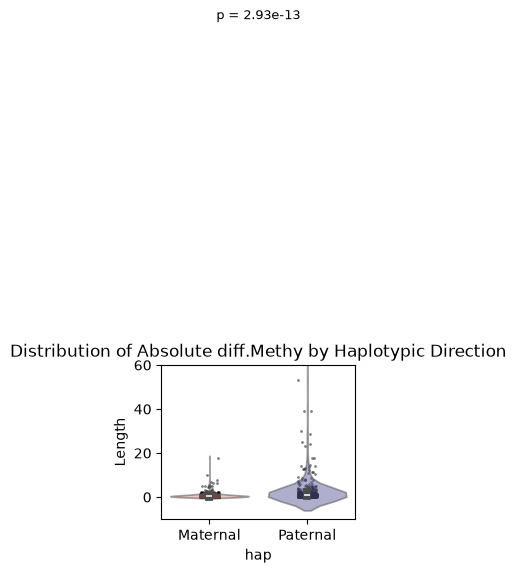

In [26]:
from scipy.stats import mannwhitneyu
dmr['kb_length'] = dmr['length'] / 1000

y = "kb_length"

plt.figure(figsize=(2.5,2))
# sns.swarmplot(data=box_df, x='Group', y='abs_diff', size=2, alpha=0.5)

# Draw jitter points first and keep them behind the box


# Draw boxplot on top
sns.violinplot(
    data=dmr, x='hap', y=y,
    #showcaps=True, showfliers=False,
    palette=color_palette,
    #boxprops=dict(zorder=3),
    #whiskerprops=dict(zorder=3),
    #capprops=dict(zorder=3),
    #?medianprops=dict(zorder=4, color='black')
    alpha = 0.5
)
sns.stripplot(
    data=dmr, x='hap', y=y,
    color='black', size=2, alpha=0.5, jitter=True,
    zorder =-1
)
# Wilcoxon rank-sum test
stat, pval = mannwhitneyu(
    dmr.loc[dmr['hap'] == 'Paternal', y],
    dmr.loc[dmr['hap'] == 'Maternal', y],
    alternative='two-sided'
)
print(f"Paternal mean : {dmr.loc[dmr['hap'] == 'Paternal', y].mean()}")
print(f"Maternal mean : {dmr.loc[dmr['hap'] == 'Maternal', y].mean()}")

print(f"Paternal median : {dmr.loc[dmr['hap'] == 'Paternal', y].median()}")
print(f"Maternal median : {dmr.loc[dmr['hap'] == 'Maternal', y].median()}")


print(f'Mann-Whitney U test stats and p-value: {stat} {pval:.2e}')
y_max = dmr[y].max()
h = y_max * 0.05
plt.plot([0, 0, 1, 1], [y_max + h, y_max + 2*h, y_max + 2*h, y_max + h], lw=1, color='black')
plt.text(0.5, y_max + 2.5*h, f'p = {pval:.2e}', ha='center', fontsize=9)
plt.ylim(-10,60)
plt.ylabel('Length')
plt.title('Distribution of Absolute diff.Methy by Haplotypic Direction')
plt.savefig(f"{figureDir}/boxplot_diff_methyl_by_hap_length_zoom.p{p}.pdf", bbox_inches='tight')
plt.show()

In [27]:
dmr_agg = dmr.groupby(['chr', 'hap']).agg({
    'abs_diff.Methy': 'sum',
    'abs_areaStat': 'sum',
    'length': 'sum',
    'burden': 'sum',
    'nCG': 'sum',
    'strand': 'count'
})

idx = pd.MultiIndex.from_product(
    [dmr['chr'].unique(), ['Maternal', 'Paternal']],
    names=['chr', 'hap']
)

dmr_agg = dmr_agg.reindex(idx).reset_index()

cols = ['abs_diff.Methy', 'abs_areaStat', 'length',
        'burden', 'nCG', 'strand']

# Fill only missing values in aggregate columns
dmr_agg[cols] = dmr_agg[cols].fillna(0)

dmr_agg                             = pd.merge(dmr_agg, fai, on='chr', how='left')
dmr_agg['total_length_percentage']  = dmr_agg['length_x'] / dmr_agg['length_y'] * 100
dmr_agg['norm_nCG']                 = dmr_agg['nCG'] / dmr_agg['length_y'] * 100
dmr_agg.head(2)

,chr,hap,abs_diff.Methy,abs_areaStat,length_x,burden,nCG,strand,length_y,total_length_percentage,norm_nCG
0,chr1,Maternal,2.915673,5853.649861,9067.0,121.061556,491.0,18.0,248387328,0.003650,0.000198
1,chr1,Paternal,0.222377,81.585512,685.0,2.219182,22.0,2.0,248387328,0.000276,0.000009


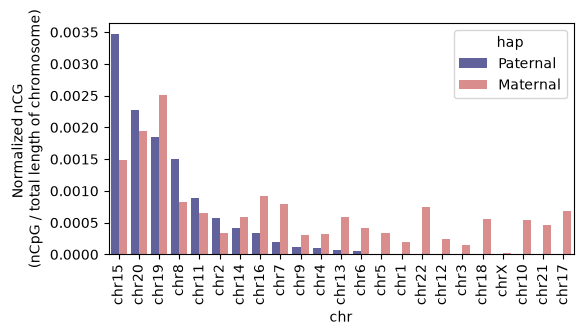

In [28]:
y='norm_nCG'
dmr_agg_plt = dmr_agg.copy()
dmr_agg_plt = dmr_agg_plt.sort_values(by = [y], ascending = False)

plt.figure(figsize=(6, 3))
sns.barplot(dmr_agg_plt, x='chr', y=y, hue='hap', palette = color_palette, order=dmr_agg_plt.loc[dmr_agg_plt['hap'] == "Paternal","chr"].to_list())
plt.xticks(rotation=90)
plt.ylabel(f"Normalized nCG \n(nCpG / total length of chromosome)")

plt.savefig(f"{figureDir}/{y}_barplot_p{p}.pdf")

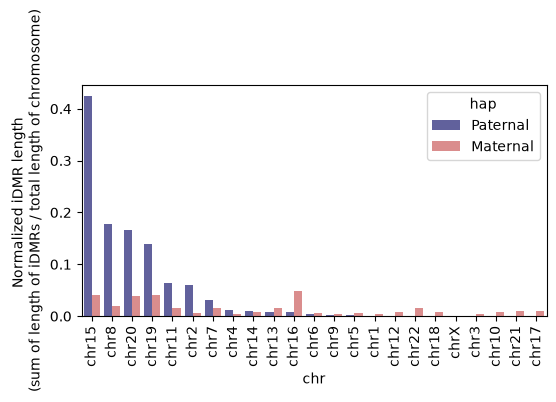

In [29]:
y='total_length_percentage'
dmr_agg_plt = dmr_agg.copy()
dmr_agg_plt = dmr_agg_plt.sort_values(by = [y], ascending = False)

plt.figure(figsize=(6, 3))
sns.barplot(dmr_agg_plt, x='chr', y=y, hue='hap', palette = color_palette, order=dmr_agg_plt.loc[dmr_agg_plt['hap'] == "Paternal","chr"].to_list())
plt.xticks(rotation=90)
plt.ylabel(f"Normalized iDMR length \n(sum of length of iDMRs / total length of chromosome)")

plt.savefig(f"{figureDir}/{y}_barplot_sumoflength.p{p}.pdf")

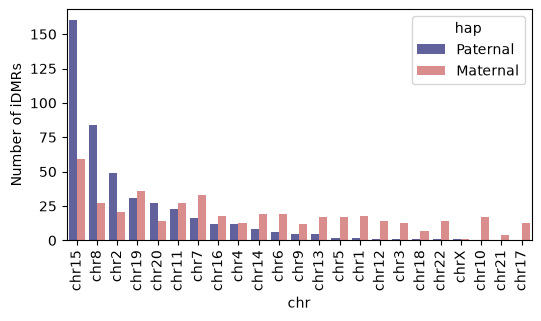

In [30]:
y='strand'
dmr_agg_plt = dmr_agg.copy()
dmr_agg_plt = dmr_agg_plt.sort_values(by = [y], ascending = False)

plt.figure(figsize=(6, 3))
sns.barplot(dmr_agg_plt, x='chr', y=y, hue='hap', palette = color_palette, order=dmr_agg_plt.loc[dmr_agg_plt['hap'] == "Paternal","chr"].to_list())
plt.xticks(rotation=90)
plt.ylabel(f"Number of iDMRs")

plt.savefig(f"{figureDir}/{y}_barplot_sumoflength.p{p}.pdf")

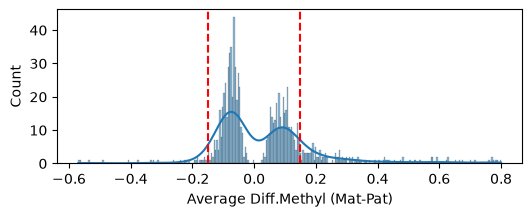

In [31]:
plt.figure(figsize = [6,2])

y = 'diff_methyl_mean'
sns.histplot(dmr , x = y, bins = 300, kde=True)

#plt.xlim(-1, 1)

for threshold in [0.15]:
    plt.axvline(threshold, color = "red", linestyle="--")
    plt.axvline(-threshold, color = "red", linestyle="--")

plt.xlabel("Average Diff.Methyl (Mat-Pat)")
#plt.axvline(min(dmr[y]), color = "grey", linestyle =":")
#plt.axvline(max(dmr[y]), color = "grey", linestyle =":")
plt.savefig(f"{figureDir}/diffMethyl_with_thresholds_zoomout_{y}.p{p}.pdf")

### plotting

In [32]:
dmr['category'] = "moderate"
dmr.loc[dmr['abs_diff.Methy'] >= 0.15, 'category'] = "strong"
dmr.groupby("category").size().reset_index(name="count")

,category,count
0,moderate,730
1,strong,150


In [33]:
dmr.groupby(["category",'hap']).size().reset_index(name="count")

,category,hap,count
0,moderate,Maternal,307
1,moderate,Paternal,423
2,strong,Maternal,126
3,strong,Paternal,24


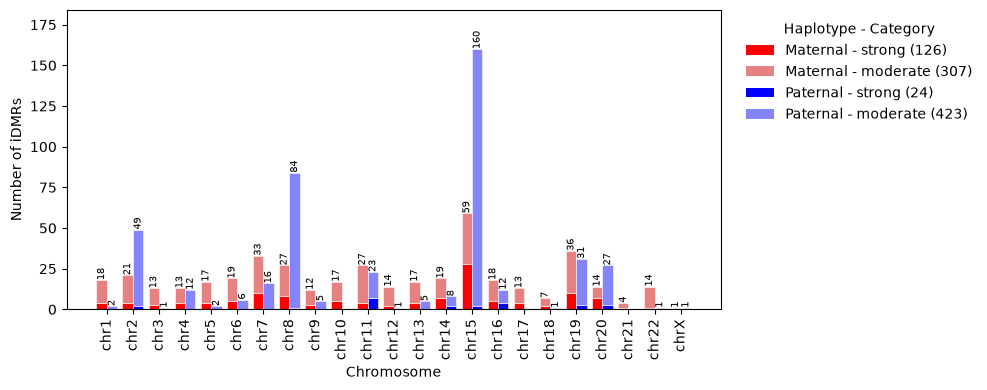

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Count iDMRs
category_counts = (
    dmr.groupby(['chr', 'hap', 'category'])
       .size()
       .reset_index(name='count')
)

chromosomes = [f"chr{i}" for i in list(range(1, 23)) + ['X']]
haps = ["Maternal", "Paternal"]
categories = ['strong', 'moderate']

category_counts['chr'] = pd.Categorical(
    category_counts['chr'],
    ordered=True,
    categories=chromosomes
)

# Unified color palette: (hap, category) -> color
palette = {
    ('Maternal', 'strong'): '#FF0000',
    ('Maternal', 'moderate'): '#e78080',
    ('Paternal', 'strong'): '#0000FF',
    ('Paternal', 'moderate'): '#8484fc',
}

# Legend label에 넣을 전체 count: hap x category 조합별 sum
legend_counts = (
    category_counts
    .groupby(['hap', 'category'], observed=False)['count']
    .sum()
)

# Plot
fig, ax = plt.subplots(figsize=(10, 4))

x = np.arange(len(chromosomes))
bar_width = 0.8 / len(haps)

bar_totals = []

for i, hap in enumerate(haps):
    bottom = np.zeros(len(chromosomes))
    xpos = x + (i - (len(haps) - 1) / 2) * bar_width

    for cat in categories:
        values = (
            category_counts[
                (category_counts['hap'] == hap) &
                (category_counts['category'] == cat)
            ]
            .set_index('chr')['count']
            .reindex(chromosomes, fill_value=0)
            .values
        )

        ax.bar(
            xpos,
            values,
            width=bar_width,
            bottom=bottom,
            color=palette[(hap, cat)],
            edgecolor='white',
            linewidth=0.4
        )

        bottom += values

    # strong + moderate가 모두 쌓인 뒤 chr x hap total 표시
    for x_i, total in zip(xpos, bottom):
        if total > 0:
            ax.text(
                x_i,
                total,
                f'{int(total)}',
                ha='center',
                va='bottom',
                fontsize=7,
                rotation=90
            )

    bar_totals.extend(bottom)

# Axis labels
ax.set_xticks(x)
ax.set_xticklabels(chromosomes, rotation=90)
ax.set_xlabel('Chromosome')
ax.set_ylabel('Number of iDMRs')

# 막대 위 숫자가 잘리지 않도록 y축 위쪽 여백 추가
max_total = max(bar_totals) if bar_totals else 0
if max_total > 0:
    ax.set_ylim(0, max_total * 1.15)

# Combined legend with total count per haplotype-category
legend_handles = [
    Patch(
        facecolor=palette[(hap, cat)],
        label=f'{hap} - {cat} ({int(legend_counts.get((hap, cat), 0))})'
    )
    for hap in haps
    for cat in categories
]

ax.legend(
    handles=legend_handles,
    title='Haplotype - Category',
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.savefig(
    os.path.join(
        figureDir,
        'idmr_count_by_chromosome_and_category.p{p}.pdf'
    ),
    bbox_inches='tight'
)

plt.show()

In [35]:
dmr.groupby(['hap', 'category']).size().reset_index(name='count')    

,hap,category,count
0,Maternal,moderate,307
1,Maternal,strong,126
2,Paternal,moderate,423
3,Paternal,strong,24


In [36]:
strong = dmr.loc[dmr['category'] == "strong"].copy()
moderate = dmr.loc[dmr['category'] == "moderate"].copy()

for tmp_df in [strong, moderate]:
    for col in ['name', 'strand','score']:
        tmp_df[col] = "."
    # BED9 expects an itemRgb-like field for display color.
    tmp_df['itemRgb'] = tmp_df['hap'].apply(lambda x: "255,0,0" if x == "Maternal" else "0,0,255")

100%|██████████| 2/2 [00:00<00:00,  3.53it/s]


<Figure size 600x300 with 0 Axes>

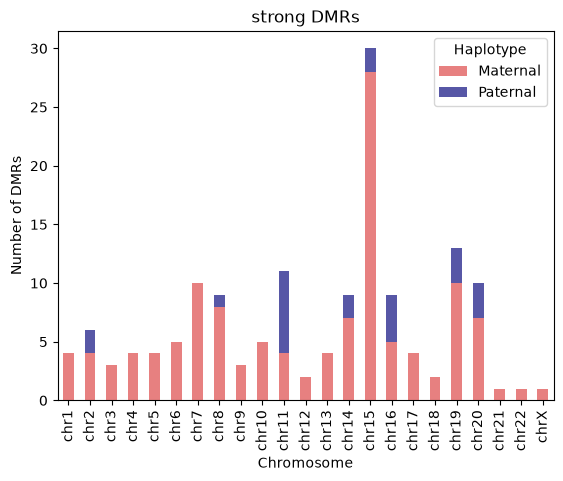

<Figure size 600x300 with 0 Axes>

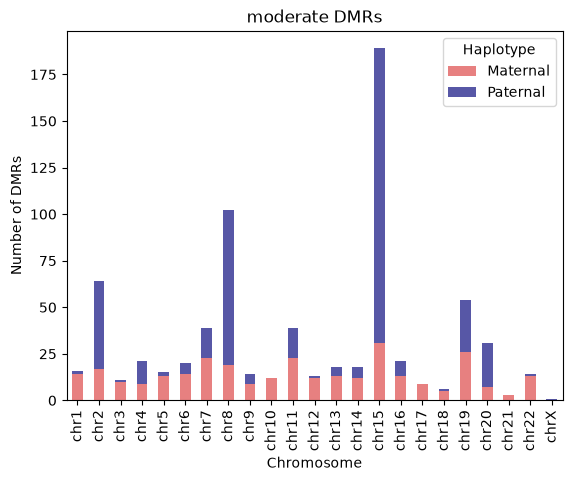

In [37]:
for y_name in tqdm.tqdm(['strong' , 'moderate']):

    plt.figure(figsize=(6,3))
    dmr_tmp= dmr.copy()
    dmr_tmp['chr'] = pd.Categorical(dmr_tmp['chr'], categories=fai['chr'] , ordered=True)
    dmr_tmp = dmr_tmp.loc[dmr_tmp['category'].isin([y_name])]

    hap_counts = (
        dmr_tmp.groupby(['chr', 'hap',], observed=False).size()
        .unstack(fill_value=0)
        .reindex(columns=['Maternal', 'Paternal'], fill_value=0)
    )

    hap_counts.plot(
        kind='bar',
        stacked=True,
        color=["#e78080", "#5757A6"]
    )

    plt.xlabel('Chromosome')
    plt.ylabel('Number of DMRs')
    plt.title(f"{y_name} DMRs")
    plt.legend(title='Haplotype')
    plt.savefig(os.path.join(figureDir, f"dmr_count_by_chromosome_and_haplotype_{y_name}.p{p}.pdf"), bbox_inches='tight')

100%|██████████| 2/2 [00:01<00:00,  1.15it/s]


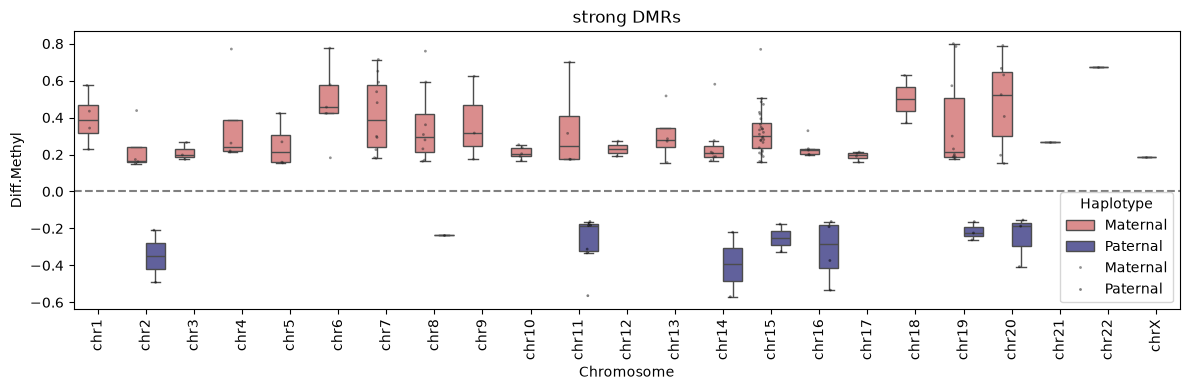

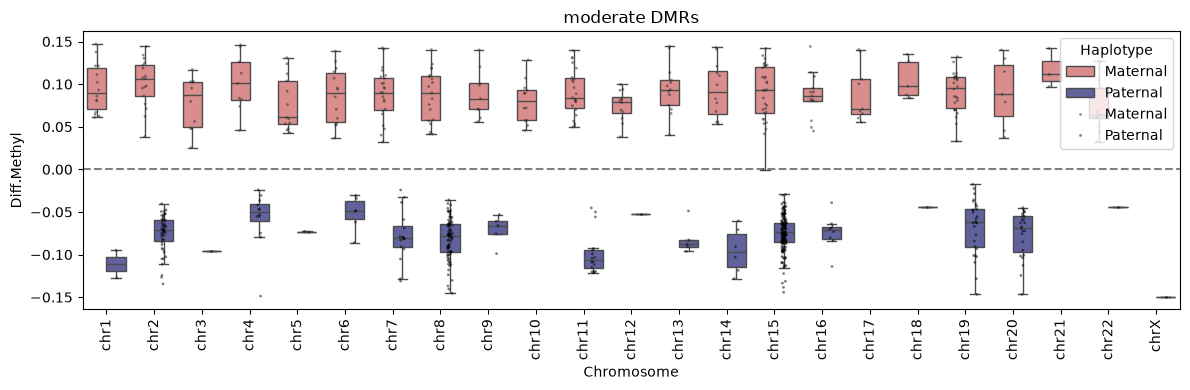

In [38]:
for y_name in tqdm.tqdm(['strong' , 'moderate']):
    dmr_tmp= dmr.copy()
    dmr_tmp['chr'] = pd.Categorical(dmr_tmp['chr'], categories=fai['chr'] , ordered=True)
    dmr_tmp = dmr_tmp.loc[dmr_tmp['category'].isin([y_name])]
    plt.figure(figsize=(12, 4))
    sns.boxplot(
        data=dmr_tmp, x='chr', y='diff_methyl_mean', hue='hap',
        hue_order=['Maternal', 'Paternal'],
        palette=color_palette, 
        showfliers=False,
    )
    sns.stripplot(data=dmr_tmp, x='chr', y='diff_methyl_mean', hue='hap', hue_order=['Maternal', 'Paternal'], 
                  dodge=True, palette='dark:black', alpha=0.5, size=2)
    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('Chromosome')
    plt.ylabel('Diff.Methyl')
    plt.title(f"{y_name} DMRs")
    plt.xticks(rotation=90)
    plt.legend(title='Haplotype')
    plt.tight_layout()
    plt.savefig(os.path.join(figureDir, f"dmr_diff_box_methy_by_chromosome_and_haplotype_{y_name}.p{p}.pdf"), bbox_inches='tight')

In [82]:
dmr.groupby(['category',"hap"]).size()

category  hap     
moderate  Maternal    307
          Paternal    423
strong    Maternal    126
          Paternal     24
dtype: int64

In [83]:
dmr.groupby(["hap"]).size()

hap
Maternal    433
Paternal    447
dtype: int64

In [84]:
dmr.groupby(["category"]).size()

category
moderate    730
strong      150
dtype: int64

## Check if iDMRs overalp with non-syntenic regions in T2T-CHM13 against GRCh38

In [39]:
nonsyntenic = pybedtools.BedTool("/weka/scratch/jhu/aphill27/references/chm13/chm13v2-unique_to_hg38.bed")
dss_dmr_bed = pybedtools.BedTool.from_dataframe(dmr)

intersect = dss_dmr_bed.intersect(nonsyntenic, loj=True, F=0.1)
intersect_df = intersect.to_dataframe(header=None, names=dmr.columns.to_list() + ['chr_nonsyntenic','start_nonsyntenic','end_nonsyntenic'])
intersect_df.head(2)


,chr,start,end,strand,nCG,areaStat,diff_methyl_mean,burden,abs_areaStat,abs_diff.Methy,hap,length,rgb,empty,kb_length,category,chr_nonsyntenic,start_nonsyntenic,end_nonsyntenic
0,chr1,2140270,2140331,+,4,21.348505,0.102170,0.408679,21.348505,0.102170,Maternal,61,#e78080,.,0.061,moderate,.,-1,-1
1,chr1,5236010,5236161,+,21,71.528896,0.060872,1.278310,71.528896,0.060872,Maternal,151,#e78080,.,0.151,moderate,.,-1,-1


In [40]:
intersect_df.loc[intersect_df['chr_nonsyntenic']!= "."]

,chr,start,end,strand,nCG,areaStat,diff_methyl_mean,burden,abs_areaStat,abs_diff.Methy,hap,length,rgb,empty,kb_length,category,chr_nonsyntenic,start_nonsyntenic,end_nonsyntenic


## Intersect with known iDMRs

In [41]:
import os
import numpy as np
import pandas as pd
import pybedtools
import matplotlib.pyplot as plt

# ============================================================
# 1. Input
# ============================================================

known_iDMR_bed = pybedtools.BedTool(
    "/path/to/project/pooch/findings/"
    "Imprinted_DMR_List_V1.LiftedOverToT2T-CHM13v2Hs1.bed"
)

dmr_cols = dmr.columns.tolist()

idmr_cols = [
    "chr_idmr",
    "start_idmr",
    "end_idmr",
    "imprinted_haplotype",
    "gene",
    "reference"
]

# Keep original DMR statistics and IDs
dmr_df = dmr.copy().reset_index(drop=True)
dmr_df["dmr_row_id"] = np.arange(len(dmr_df))

# BED requires chr, start, end as first 3 columns
dmr_df = dmr_df[
    ["chr", "start", "end"] +
    [c for c in dmr_df.columns if c not in ["chr", "start", "end"]]
]

dss_dmr_bed = pybedtools.BedTool.from_dataframe(dmr_df)

# ============================================================
# 2. Read known iDMR annotations
# ============================================================

known_df = known_iDMR_bed.to_dataframe(
    header=None,
    names=idmr_cols
)

known_df["start_idmr"] = pd.to_numeric(
    known_df["start_idmr"]
)

known_df["end_idmr"] = pd.to_numeric(
    known_df["end_idmr"]
)

known_df["id_idmr"] = (
    known_df["chr_idmr"].astype(str) + ":" +
    known_df["start_idmr"].astype(str) + "-" +
    known_df["end_idmr"].astype(str)
)

# Unique row ID, preserving distinct annotations
known_df["idmr_row_id"] = np.arange(len(known_df))

# ============================================================
# 3. Calculate actual overlap pairs
# ============================================================

# Use a temporary BED with unique IDs to avoid float precision
# differences introduced by bedtools output formatting.

dmr_bed_small = pybedtools.BedTool.from_dataframe(
    dmr_df[["chr", "start", "end", "dmr_row_id"]]
)

known_bed_small = pybedtools.BedTool.from_dataframe(
    known_df[
        ["chr_idmr", "start_idmr", "end_idmr", "idmr_row_id"]
    ]
)

# f=0.001: at least 0.1% of DSS DMR must overlap
overlap_bed = dmr_bed_small.intersect(
    known_bed_small,
    wa=True,
    wb=True,
    f=0.001
)

overlap_df = overlap_bed.to_dataframe(
    header=None,
    names=[
        "chr", "start", "end", "dmr_row_id",
        "chr_idmr", "start_idmr", "end_idmr", "idmr_row_id"
    ]
)

overlap_df = overlap_df[
    ["dmr_row_id", "idmr_row_id"]
].drop_duplicates()

# Attach original full-precision statistics
overlap_df = overlap_df.merge(
    dmr_df,
    on="dmr_row_id",
    how="left",
    validate="many_to_one"
)

overlap_df = overlap_df.merge(
    known_df,
    on="idmr_row_id",
    how="left",
    validate="many_to_one"
)

# ============================================================
# 4. Normalize directions and numeric columns
# ============================================================

dmr_df["diff_methyl_mean"] = pd.to_numeric(
    dmr_df["diff_methyl_mean"],
    errors="coerce"
)

overlap_df["diff_methyl_mean"] = pd.to_numeric(
    overlap_df["diff_methyl_mean"],
    errors="coerce"
)

# Normalize haplotype strings
for col in ["hap", "imprinted_haplotype"]:
    overlap_df[col] = (
        overlap_df[col]
        .astype(str)
        .str.strip()
        .str.capitalize()
    )

# Important: both columns must represent the
# hypermethylated parental haplotype.

# ============================================================
# 5. Classify individual overlap pairs
# ============================================================

overlap_df["pair_cat"] = np.where(
    overlap_df["hap"] == overlap_df["imprinted_haplotype"],
    "Matched",
    "Mismatched"
)

overlap_df["sign"] = np.sign(
    overlap_df["diff_methyl_mean"]
)

# ============================================================
# 6. Summarize known iDMRs
# ============================================================

category_priority = {
    "strong": 3,
    "moderate": 2,
    "subtle": 1
}

def summarize_idmr(sub):

    signs = sub["sign"].dropna()

    has_positive = (signs > 0).any()
    has_negative = (signs < 0).any()

    has_matched = (sub["pair_cat"] == "Matched").any()

    if has_positive and has_negative:
        cat = "Mixed_Sign"
    elif has_matched:
        cat = "Matched"
    else:
        cat = "Mismatched"

    # Representative DMR: strongest category
    ranked = sub.assign(
        category_rank=sub["category"].map(category_priority)
    ).sort_values(
        "category_rank",
        ascending=False
    )

    representative = ranked.iloc[0]

    return pd.Series({
        "cat": cat,
        "category": representative["category"],
        "n_overlapping_dmrs": sub["dmr_row_id"].nunique(),
        "n_matched_dmrs": (
            sub.loc[
                sub["pair_cat"] == "Matched",
                "dmr_row_id"
            ].nunique()
        ),
        "n_mismatched_dmrs": (
            sub.loc[
                sub["pair_cat"] == "Mismatched",
                "dmr_row_id"
            ].nunique()
        ),
        "representative_dmr_id": representative["dmr_row_id"]
    })


if not overlap_df.empty:

    idmr_summary = (
        overlap_df.groupby("idmr_row_id")
        .apply(summarize_idmr)
        .reset_index()
    )

else:

    idmr_summary = pd.DataFrame(
        columns=[
            "idmr_row_id",
            "cat",
            "category",
            "n_overlapping_dmrs",
            "n_matched_dmrs",
            "n_mismatched_dmrs",
            "representative_dmr_id"
        ]
    )

# ============================================================
# 7. Include known iDMRs without DSS overlap
# ============================================================

known_summary = known_df.merge(
    idmr_summary,
    on="idmr_row_id",
    how="left",
    validate="one_to_one"
)

known_summary["cat"] = known_summary["cat"].fillna(
    "Missing"
)

known_summary["category"] = known_summary["category"].fillna(
    "missing"
)

known_summary["n_overlapping_dmrs"] = (
    known_summary["n_overlapping_dmrs"]
    .fillna(0)
    .astype(int)
)

known_summary["n_matched_dmrs"] = (
    known_summary["n_matched_dmrs"]
    .fillna(0)
    .astype(int)
)

known_summary["n_mismatched_dmrs"] = (
    known_summary["n_mismatched_dmrs"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# 8. Identify novel DSS DMRs
# ============================================================

overlapping_dmr_ids = set(
    overlap_df["dmr_row_id"].unique()
)

novel_df = dmr_df.loc[
    ~dmr_df["dmr_row_id"].isin(overlapping_dmr_ids)
].copy()

novel_df["cat"] = "Novel"

novel_df["id_dss"] = (
    novel_df["chr"].astype(str) + ":" +
    novel_df["start"].astype(str) + "-" +
    novel_df["end"].astype(str)
)

# ============================================================
# 9. Summary statistics
# ============================================================

print("\nKnown iDMR classification:")
print(known_summary["cat"].value_counts())

print("\nNovel DSS DMRs:")
print(len(novel_df))

n_known = len(known_summary)
n_recovered = (
    known_summary["cat"] != "Missing"
).sum()

print(
    f"\nKnown iDMR overlap recovery: "
    f"{n_recovered}/{n_known} "
    f"({n_recovered / n_known * 100:.2f}%)"
)

# DSS DMRs overlapping Matched known iDMRs
matched_ids = known_summary.loc[
    known_summary["cat"] == "Matched", "idmr_row_id"
]

matched_dmrs = overlap_df.loc[
    (overlap_df["idmr_row_id"].isin(matched_ids)) &
    (overlap_df["pair_cat"] == "Matched")
]

# Count unique DSS DMRs by category
matched_counts = (
    matched_dmrs
    .drop_duplicates(subset="dmr_row_id")
    .groupby("category")
    .size()
    .reindex(["strong", "moderate", "subtle"], fill_value=0)
)

print("\nDSS DMRs overlapping Matched known iDMRs:")
print(matched_counts)
print(f"Total unique DSS DMRs: {matched_counts.sum()}")

# ============================================================
# 12. Save tables
# ============================================================

known_summary.to_csv(
    os.path.join(figureDir, "known_iDMR_recovery.tsv"),
    sep="\t",
    index=False
)

novel_df.to_csv(
    os.path.join(figureDir, "novel_DSS_DMRs.tsv"),
    sep="\t",
    index=False
)

overlap_df.to_csv(
    os.path.join(figureDir, "DSS_known_iDMR_overlap_pairs.tsv"),
    sep="\t",
    index=False
)


Known iDMR classification:
cat
Matched       137
Missing        48
Mixed_Sign      8
Name: count, dtype: int64

Novel DSS DMRs:
729

Known iDMR overlap recovery: 145/193 (75.13%)

DSS DMRs overlapping Matched known iDMRs:
category
strong      100
moderate     33
subtle        0
dtype: int64
Total unique DSS DMRs: 133


In [42]:
# Total input DSS DMRs
n_total = dmr_df["dmr_row_id"].nunique()

# DSS DMRs overlapping at least one known iDMR
n_overlap = overlap_df["dmr_row_id"].nunique()

# DSS DMRs without known iDMR overlap
n_novel = novel_df["dmr_row_id"].nunique()

print("Total DSS DMRs:", n_total)
print("Overlapping known iDMRs:", n_overlap)
print("Non-overlapping DSS DMRs:", n_novel)
print("Sum:", n_overlap + n_novel)

assert n_total == n_overlap + n_novel

Total DSS DMRs: 880
Overlapping known iDMRs: 151
Non-overlapping DSS DMRs: 729
Sum: 880


In [43]:
# Unique DSS DMRs by overlap direction
overlap_summary = (
    overlap_df.groupby("dmr_row_id")
    .agg(
        category=("category", "first"),
        has_matched=("pair_cat", lambda x: (x == "Matched").any()),
        has_mismatched=("pair_cat", lambda x: (x == "Mismatched").any())
    )
    .reset_index()
)

overlap_summary["classification"] = np.select(
    [
        overlap_summary["has_matched"] &
        overlap_summary["has_mismatched"],

        overlap_summary["has_matched"],

        overlap_summary["has_mismatched"]
    ],
    [
        "Both",
        "Matched",
        "Mismatched"
    ],
    default="Unknown"
)

print(
    pd.crosstab(
        overlap_summary["classification"],
        overlap_summary["category"]
    )
)

print("\nTotal:", len(overlap_summary))

category        moderate  strong
classification                  
Matched               34     109
Mismatched             8       0

Total: 151


In [44]:
# Count unique DSS DMRs per known iDMR
idmr_to_dss = (
    overlap_df.groupby("idmr_row_id")
    .agg(
        n_dss=("dmr_row_id", "nunique"),
        dss_ids=("dmr_row_id", lambda x: sorted(set(x)))
    )
    .reset_index()
    .merge(
        known_df[
            ["idmr_row_id", "id_idmr", "gene"]
        ],
        on="idmr_row_id",
        how="left"
    )
)

multiple_dss_per_idmr = idmr_to_dss.loc[
    idmr_to_dss["n_dss"] > 1
].sort_values("n_dss", ascending=False)

print(
    "Known iDMRs overlapping multiple DSS DMRs:",
    len(multiple_dss_per_idmr)
)

display(multiple_dss_per_idmr)

Known iDMRs overlapping multiple DSS DMRs: 9


,idmr_row_id,n_dss,dss_ids,id_idmr,gene
28,42,3,"[170, 171, 172]",chr15:21296256-21301762,"MIR4508,MKRN3"
37,52,3,"[215, 216, 217]",chr15:21591584-21596455,RP11-484P15.1
3,5,2,"[11, 12]",chr1:67924206-67929467,"DIRAS3,DIRAS3_Ex2,GNG12-AS1"
20,31,2,"[113, 114]",chr13:59487091-59488917,TARDBPP2
34,48,2,"[197, 198]",chr15:21420762-21422619,NDN
56,76,2,"[320, 321]",chr15:22614163-22616870,SNRPN
58,78,2,"[334, 335]",chr15:22688234-22693913,"SNURF,SNRPN,RP11-701H24.9"
72,95,2,"[381, 382]",chr16:3391703-3393524,"MTRNR2L4,LA16c-306E5.2"
138,181,2,"[850, 851]",chr8:95243985-95245657,CDH17


Known-only iDMRs: 48
Overlapping known iDMRs: 145
Overlapping DSS DMRs: 151
Novel autosomal DSS DMRs: 727
Novel chrX DSS DMRs: 2


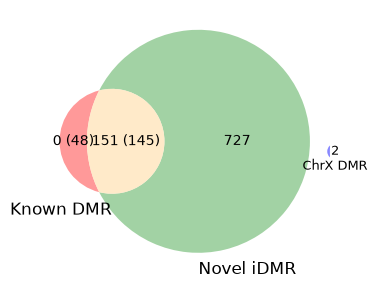

In [45]:
import os
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib.patches import Circle

# ============================================================
# 1. Calculate counts directly from DataFrames
# ============================================================

# Known iDMRs without DSS overlap
n_known_only = (
    known_summary.loc[
        known_summary["cat"] == "Missing",
        "idmr_row_id"
    ].nunique()
)

# Known iDMRs overlapping DSS DMRs
n_overlap_idmr = overlap_df["idmr_row_id"].nunique()

# DSS DMRs overlapping known iDMRs
n_overlap_dss = overlap_df["dmr_row_id"].nunique()

# DSS DMRs without known iDMR overlap
n_novel = novel_df["dmr_row_id"].nunique()

# Separate chrX DMRs from novel DMRs
n_chrx = novel_df.loc[
    novel_df["chr"] == "chrX",
    "dmr_row_id"
].nunique()

n_novel_autosomes = n_novel - n_chrx

# Validate DSS DMR counts
assert (
    n_overlap_dss + n_novel == dmr_df["dmr_row_id"].nunique()
), "DSS DMR counts do not match the input!"

print(f"Known-only iDMRs: {n_known_only}")
print(f"Overlapping known iDMRs: {n_overlap_idmr}")
print(f"Overlapping DSS DMRs: {n_overlap_dss}")
print(f"Novel autosomal DSS DMRs: {n_novel_autosomes}")
print(f"Novel chrX DSS DMRs: {n_chrx}")

# ============================================================
# 2. Plot
# ============================================================

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

fig, ax = plt.subplots(figsize=(4, 3))

v = venn2(
    subsets=(
        n_known_only,
        n_novel_autosomes,
        n_overlap_idmr
    ),
    set_labels=("Known DMR", "Novel iDMR"),
    set_colors=("#FF8080", "#8BC78D"),
    alpha=0.8,
    ax=ax
)

# Main count = DSS DMRs
# Parentheses = known iDMRs
v.get_label_by_id("10").set_text(f"0 ({n_known_only})")
v.get_label_by_id("11").set_text(
    f"{n_overlap_dss} ({n_overlap_idmr})"
)
v.get_label_by_id("01").set_text(str(n_novel_autosomes))

# Separate chrX DMRs
ax.add_patch(
    Circle(
        (0.75, -0.05),
        radius=0.035,
        color="#8080FF",
        alpha=0.85
    )
)

ax.text(
    0.75, -0.05,
    str(n_chrx),
    ha="center",
    va="center",
    fontsize=9
)

ax.text(
    0.75, -0.14,
    "ChrX DMR",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    os.path.join(figureDir, f"venn_known_novel_chrX.p{p}.pdf"),
    bbox_inches="tight"
)

plt.show()

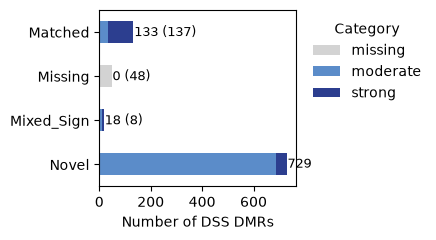

In [77]:
import matplotlib.pyplot as plt
import pandas as pd

color_diff_dmr = {
    "strong": "#2C3E8F",
    "moderate": "#5B8CC9",
    "missing": "#D3D3D3"
}

cat_order = ["Novel", "Mixed_Sign", "Missing", "Matched"]
category_order = ["missing", "moderate", "strong"]

# Known iDMR counts
known_counts = (
    known_summary
    .groupby(["cat", "category"])
    .size()
    .unstack(fill_value=0)
)

# DSS DMR counts by known iDMR classification
dss_classified = (
    overlap_df
    .merge(
        known_summary[["idmr_row_id", "cat"]],
        on="idmr_row_id",
        how="left"
    )
    .sort_values("idmr_row_id")
    .drop_duplicates("dmr_row_id")
)

dss_counts = (
    dss_classified
    .groupby(["cat", "category"])
    .size()
    .unstack(fill_value=0)
)

# Novel DSS DMRs
novel_counts = (
    novel_df["category"]
    .value_counts()
    .to_frame()
    .T
)
novel_counts.index = ["Novel"]

# Missing known iDMRs have no corresponding DSS DMRs
# Represent these as a separate gray segment
missing_count = int(
    (known_summary["cat"] == "Missing").sum()
)

plot_counts = pd.concat(
    [dss_counts, novel_counts],
    axis=0
).reindex(
    index=cat_order,
    columns=category_order,
    fill_value=0
).fillna(0)

# Missing bar represents known iDMRs, not DSS DMRs
plot_counts.loc["Missing", "missing"] = missing_count

fig, ax = plt.subplots(figsize=(4.5, 2.5))

plot_counts.plot(
    kind="barh",
    stacked=True,
    color=[color_diff_dmr[c] for c in category_order],
    ax=ax
)

for i, cat in enumerate(plot_counts.index):

    n_dss = int(plot_counts.loc[cat].sum())

    if cat == "Novel":
        label = f"{n_dss}"

    elif cat == "Missing":
        label = f"0 ({missing_count})"

    else:
        n_idmr = int(
            (known_summary["cat"] == cat).sum()
        )
        label = f"{n_dss} ({n_idmr})"

    ax.text(
        n_dss + 3,
        i,
        label,
        va="center",
        fontsize=9
    )

ax.set_xlabel("Number of DSS DMRs")
ax.set_ylabel("")

ax.legend(
    title="Category",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.savefig(
    os.path.join(figureDir, f"iDMR_cat_barplot.p{p}.pdf"),
    bbox_inches="tight"
)
plt.show()

DSS DMR classification:
cat
Novel         729
Matched       133
Mixed_Sign     18
Mismatched      0
Name: count, dtype: int64


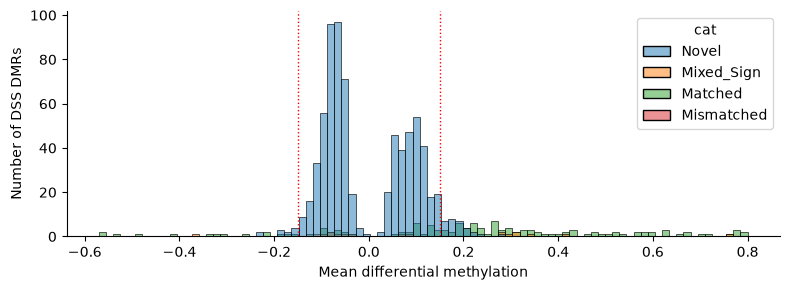

/tmp/ipykernel_322382/2643044372.py:127: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


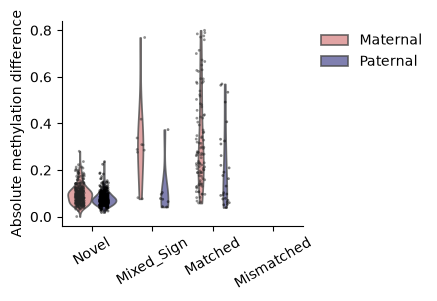

/tmp/ipykernel_322382/2643044372.py:236: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


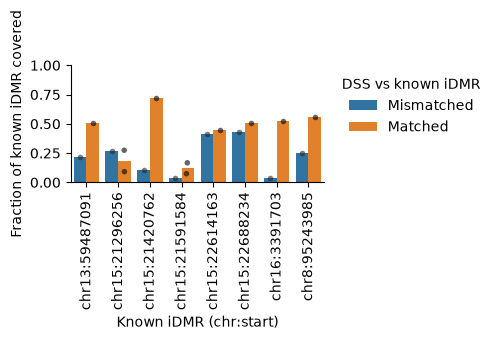

In [48]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

color_palette = {
    "Maternal": "#e78080",
    "Paternal": "#5757A6"
}

cat_order = ["Novel", "Mixed_Sign", "Matched", "Mismatched"]

# ============================================================
# 1. Prepare DSS DMR-level dataframe
# ============================================================

# Attach known iDMR classification to overlap pairs
overlap_plot = overlap_df.merge(
    known_summary[["idmr_row_id", "cat"]],
    on="idmr_row_id",
    how="left",
    validate="many_to_one"
)

# Assign one classification per DSS DMR
# Priority: Mixed_Sign > Matched > Mismatched
cat_priority = {
    "Mixed_Sign": 3,
    "Matched": 2,
    "Mismatched": 1
}

overlap_plot["cat_rank"] = overlap_plot["cat"].map(cat_priority)

overlap_plot = (
    overlap_plot
    .sort_values("cat_rank", ascending=False)
    .drop_duplicates("dmr_row_id")
)

# Include novel DSS DMRs
novel_plot = novel_df.copy()
novel_plot["cat"] = "Novel"

plt_df = pd.concat(
    [overlap_plot, novel_plot],
    ignore_index=True
)

# Numeric conversion
for col in ["diff_methyl_mean", "abs_diff.Methy"]:
    plt_df[col] = pd.to_numeric(
        plt_df[col],
        errors="coerce"
    )

plt_df["cat"] = pd.Categorical(
    plt_df["cat"],
    categories=cat_order,
    ordered=True
)

# Validate counts
assert plt_df["dmr_row_id"].nunique() == dmr_df["dmr_row_id"].nunique()

print("DSS DMR classification:")
print(plt_df["cat"].value_counts())

# ============================================================
# 2. Histogram of differential methylation
# ============================================================

fig, ax = plt.subplots(figsize=(8, 3))

sns.histplot(
    data=plt_df,
    x="diff_methyl_mean",
    hue="cat",
    hue_order=cat_order,
    binwidth=0.015,
    common_bins=True,
    multiple="layer",
    alpha=0.5,
    ax=ax
)

ax.axvline(0.15, linestyle=":", color="red", linewidth=1)
ax.axvline(-0.15, linestyle=":", color="red", linewidth=1)

ax.set_xlabel("Mean differential methylation")
ax.set_ylabel("Number of DSS DMRs")

sns.despine()
plt.tight_layout()

plt.savefig(
    os.path.join(figureDir, f"histogram_by_category.p{p}.pdf"),
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 3. Violin + strip plot
# ============================================================

fig, ax = plt.subplots(figsize=(4.5, 3))

sns.violinplot(
    data=plt_df,
    x="cat",
    y="abs_diff.Methy",
    hue="hap",
    order=cat_order,
    hue_order=["Maternal", "Paternal"],
    palette=color_palette,
    inner=None,
    cut=0,
    alpha=0.8,
    ax=ax
)

sns.stripplot(
    data=plt_df,
    x="cat",
    y="abs_diff.Methy",
    hue="hap",
    order=cat_order,
    hue_order=["Maternal", "Paternal"],
    dodge=True,
    color="black",
    alpha=0.5,
    size=2,
    jitter=0.15,
    ax=ax
)

# Remove duplicated legend entries
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles[:2],
    labels[:2],
    title="",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.set_xlabel("")
ax.set_ylabel("Absolute methylation difference")
ax.tick_params(axis="x", rotation=30)

sns.despine()
plt.tight_layout()

plt.savefig(
    os.path.join(figureDir, f"violin_by_category.p{p}.pdf"),
    bbox_inches="tight"
)

plt.show()
# ============================================================
# Mixed-sign known iDMR coverage plot
# ============================================================

mixed_ids = known_summary.loc[
    known_summary["cat"] == "Mixed_Sign",
    "idmr_row_id"
]

mixed_sign_table = overlap_df.loc[
    overlap_df["idmr_row_id"].isin(mixed_ids)
].copy()

mixed_sign_table["direction_match"] = (
    mixed_sign_table["hap"].astype(str).str.strip().str.capitalize()
    ==
    mixed_sign_table["imprinted_haplotype"].astype(str).str.strip().str.capitalize()
)

# Calculate overlap length
mixed_sign_table["overlap_len"] = np.maximum(
    0,
    np.minimum(
        mixed_sign_table["end"],
        mixed_sign_table["end_idmr"]
    ) -
    np.maximum(
        mixed_sign_table["start"],
        mixed_sign_table["start_idmr"]
    )
)

mixed_sign_table["length_known_iDMR"] = (
    mixed_sign_table["end_idmr"] -
    mixed_sign_table["start_idmr"]
)

mixed_sign_table["coverage"] = (
    mixed_sign_table["overlap_len"] /
    mixed_sign_table["length_known_iDMR"]
)

mixed_sign_table["id_idmr"] = (
    mixed_sign_table["chr_idmr"].astype(str) + ":" +
    mixed_sign_table["start_idmr"].astype(str)
)

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(5, 3))

palette = {
    False: "#1F77B4",
    True: "#FF7F0E"
}

sns.barplot(
    data=mixed_sign_table,
    x="id_idmr",
    y="coverage",
    hue="direction_match",
    hue_order=[False, True],
    palette=palette,
    errorbar=None,
    ax=ax
)

sns.stripplot(
    data=mixed_sign_table,
    x="id_idmr",
    y="coverage",
    hue="direction_match",
    hue_order=[False, True],
    dodge=True,
    color="black",
    alpha=0.6,
    size=4,
    ax=ax
)

# Remove duplicate legend
handles, labels = ax.get_legend_handles_labels()

ax.legend(
    handles[:2],
    ["Mismatched", "Matched"],
    title="DSS vs known iDMR",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.set_xlabel("Known iDMR (chr:start)")
ax.set_ylabel("Fraction of known iDMR covered")
ax.set_ylim(0, 1)

ax.tick_params(axis="x", rotation=90)

sns.despine()
plt.tight_layout()

plt.savefig(
    os.path.join(figureDir, f"mixed_sign_coverage.p{p}.pdf"),
    bbox_inches="tight"
)

plt.show()

## Novel 

In [215]:
novel = intersect_df.loc[(intersect_df['cat'] == "Novel")]

novel['abs_diff.Methy'] = novel['abs_diff.Methy'].astype(float)

novel.loc[novel['abs_diff.Methy'] > 0.15].sort_values(by = 'abs_areaStat', ascending=False)

,chr,start,end,strand,nCG,areaStat,diff_methyl_mean,burden,abs_areaStat,abs_diff.Methy,...,imprinted_haplotype,gene,reference,id_idmr,id_dss,id,cat,known,DMR_detect,universal_name
580,chr20,45254312,45293576,-,411,-6451.041971,-0.187823,77.195056,6451.041971,0.187823,...,.,.,.,.:-1,chr20:45254312,chr20:45254312,Novel,Novel iDMR,Detected as DMR,chr20_45254312_45293576
59,chr11,2740533,2770662,-,259,-3884.635807,-0.18303,47.40468,3884.635807,0.183030,...,.,.,.,.:-1,chr11:2740533,chr11:2740533,Novel,Novel iDMR,Detected as DMR,chr11_2740533_2770662
427,chr19,1435202,1437053,+,174,1404.388758,0.192288,33.458132,1404.388758,0.192288,...,.,.,.,.:-1,chr19:1435202,chr19:1435202,Novel,Novel iDMR,Detected as DMR,chr19_1435202_1437053
60,chr11,2772623,2783329,-,90,-1299.912435,-0.185209,16.668796,1299.912435,0.185209,...,.,.,.,.:-1,chr11:2772623,chr11:2772623,Novel,Novel iDMR,Detected as DMR,chr11_2772623_2783329
36,chr10,134520078,134521470,+,122,1076.432634,0.204115,24.902015,1076.432634,0.204115,...,.,.,.,.:-1,chr10:134520078,chr10:134520078,Novel,Novel iDMR,Detected as DMR,chr10_134520078_134521470
35,chr10,134479155,134481631,+,173,993.48222,0.16703,28.89621,993.48222,0.167030,...,.,.,.,.:-1,chr10:134479155,chr10:134479155,Novel,Novel iDMR,Detected as DMR,chr10_134479155_134481631
399,chr16,14989789,14991527,+,123,849.737292,0.223155,27.448089,849.737292,0.223155,...,.,.,.,.:-1,chr16:14989789,chr16:14989789,Novel,Novel iDMR,Detected as DMR,chr16_14989789_14991527
130,chr14,88445482,88446014,+,45,461.27153,0.212902,9.580612,461.27153,0.212902,...,.,.,.,.:-1,chr14:88445482,chr14:88445482,Novel,Novel iDMR,Detected as DMR,chr14_88445482_88446014
409,chr17,42896303,42896952,+,71,424.131524,0.158414,11.247362,424.131524,0.158414,...,.,.,.,.:-1,chr17:42896303,chr17:42896303,Novel,Novel iDMR,Detected as DMR,chr17_42896303_42896952
414,chr17,74036554,74038403,+,47,416.059428,0.213236,10.022101,416.059428,0.213236,...,.,.,.,.:-1,chr17:74036554,chr17:74036554,Novel,Novel iDMR,Detected as DMR,chr17_74036554_74038403


## Missing

In [61]:
import os
import numpy as np
import pandas as pd
import pybedtools
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"

swap_samples = {"HG03579", "HG02717", "HG02451"}

hap_order = ["hap2", "hap1"]

palette = {
    "hap2": "#e88080",
    "hap1": "#8080b3"
}

min_pairs = 3

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

os.makedirs(figureDir, exist_ok=True)

In [62]:
missing_known = (
    known_summary.loc[
        known_summary["cat"] == "Missing"
    ]
    .copy()
)

missing_known["id"] = (
    missing_known["chr_idmr"].astype(str) + "_" +
    missing_known["start_idmr"].astype(str) + "_" +
    missing_known["end_idmr"].astype(str)
)

missing_df = (
    missing_known[
        ["chr_idmr", "start_idmr", "end_idmr", "id"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Missing known iDMRs:", len(missing_df))
display(missing_df.head())

Missing known iDMRs: 48


,chr_idmr,start_idmr,end_idmr,id
0,chr1,11044370,11044544,chr1_11044370_11044544
1,chr1,21120031,21120143,chr1_21120031_21120143
2,chr1,227504793,227504903,chr1_227504793_227504903
3,chr10,13172944,13173273,chr10_13172944_13173273
4,chr10,98458604,98458947,chr10_98458604_98458947


In [63]:
na_bed = pybedtools.BedTool(
    "/path/to/project/pooch/"
    "pooch_data/05.dss_using_123_pairing/"
    "dmls.N05_filt.all_chr.NA.bed.gz"
)

missing_bed = pybedtools.BedTool.from_dataframe(
    missing_df[
        ["chr_idmr", "start_idmr", "end_idmr"]
    ]
)

intersect_df_missing_na = (
    missing_bed
    .intersect(na_bed, loj=True)
    .to_dataframe(
        header=None,
        names=[
            "chr_idmr", "start_idmr", "end_idmr",
            "chr_na", "start_na", "end_na"
        ]
    )
)

intersect_df_missing_na["id"] = (
    intersect_df_missing_na["chr_idmr"].astype(str) + "_" +
    intersect_df_missing_na["start_idmr"].astype(str) + "_" +
    intersect_df_missing_na["end_idmr"].astype(str)
)

display(intersect_df_missing_na.head())

,chr_idmr,start_idmr,end_idmr,chr_na,start_na,end_na,id
0,chr1,11044370,11044544,.,-1,-1,chr1_11044370_11044544
1,chr1,21120031,21120143,.,-1,-1,chr1_21120031_21120143
2,chr1,227504793,227504903,.,-1,-1,chr1_227504793_227504903
3,chr10,13172944,13173273,.,-1,-1,chr10_13172944_13173273
4,chr10,98458604,98458947,.,-1,-1,chr10_98458604_98458947


In [64]:
na_overlap_counts = (
    intersect_df_missing_na
    .assign(
        has_overlap=lambda x: x["chr_na"].ne(".")
    )
    .groupby("id", as_index=False)
    .agg(
        na_overlap_count=("has_overlap", "sum")
    )
)

print("Missing iDMRs overlapping NA intervals:")
print((na_overlap_counts["na_overlap_count"] > 0).sum())

print("\nNA overlap count distribution:")
print(
    na_overlap_counts["na_overlap_count"]
    .value_counts()
    .sort_index()
)

display(na_overlap_counts.head())

Missing iDMRs overlapping NA intervals:
5

NA overlap count distribution:
na_overlap_count
0     43
1      2
53     1
78     1
95     1
Name: count, dtype: int64


,id,na_overlap_count
0,chr10_13172944_13173273,0
1,chr10_98458604_98458947,0
2,chr12_130374845_130375163,0
3,chr12_14651159_14651402,0
4,chr12_3845430_3845920,0


In [65]:
import glob
from tqdm.auto import tqdm

files = sorted(glob.glob(
    "/home/jhu/jkim789/projects_aphill27/projects/pooch/"
    "pooch_data/04.methyl_chm13/within_known_iDMRs/winnow*bed"
))

dfs = []

for f in tqdm(files):

    df_tmp = pd.read_csv(
        f,
        sep="\t",
        header=None,
        names=[
            "idmr_chr",
            "idmr_start",
            "idmr_end",
            "coverage",
            "methylated"
        ]
    )

    if df_tmp.empty:
        print("Empty file:", f)
        continue

    filename = os.path.basename(f)

    sample = filename.split("-")[2]
    hap = filename.split(".")[-3]

    if sample in swap_samples:
        hap = {"hap1": "hap2", "hap2": "hap1"}[hap]

    df_tmp["sample"] = sample
    df_tmp["hap"] = hap

    dfs.append(df_tmp)

if not dfs:
    raise ValueError("No methylation data found.")

methyl = pd.concat(dfs, ignore_index=True)

methyl["coverage"] = pd.to_numeric(
    methyl["coverage"], errors="coerce"
)

methyl["methylated"] = pd.to_numeric(
    methyl["methylated"], errors="coerce"
)

methyl["methylation"] = (
    methyl["methylated"] /
    methyl["coverage"].replace(0, np.nan)
)

methyl["id"] = (
    methyl["idmr_chr"].astype(str) + "_" +
    methyl["idmr_start"].astype(str) + "_" +
    methyl["idmr_end"].astype(str)
)

print("Files:", len(files))
print("Samples:", methyl["sample"].nunique())
print("Regions:", methyl["id"].nunique())

display(methyl.head())

/weka/home/jhu/jkim789/miniforge3/envs/python_plot/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 246/246 [00:01<00:00, 194.93it/s]


Files: 246
Samples: 123
Regions: 13942


,idmr_chr,idmr_start,idmr_end,coverage,methylated,sample,hap,methylation,id
0,chr1,11044377,11044378,44,5,HG002,hap1,0.113636,chr1_11044377_11044378
1,chr1,11044412,11044413,43,3,HG002,hap1,0.069767,chr1_11044412_11044413
2,chr1,11044419,11044420,39,6,HG002,hap1,0.153846,chr1_11044419_11044420
3,chr1,11044423,11044424,43,5,HG002,hap1,0.116279,chr1_11044423_11044424
4,chr1,11044425,11044426,42,5,HG002,hap1,0.119048,chr1_11044425_11044426


In [66]:
methyl_cols = [
    "idmr_chr", "idmr_start", "idmr_end",
    "coverage", "methylated", "sample", "hap"
]

methyl_bed = pybedtools.BedTool.from_dataframe(
    methyl[methyl_cols]
)

missing_bed = pybedtools.BedTool.from_dataframe(
    missing_df[
        ["chr_idmr", "start_idmr", "end_idmr"]
    ]
)

hprc_methyl = missing_bed.intersect(
    methyl_bed,
    wa=True,
    wb=True
)

hprc_methyl_df = hprc_methyl.to_dataframe(
    header=None,
    names=[
        "chr_idmr", "start_idmr", "end_idmr"
    ] + methyl_cols
)

print("Overlapping methylation records:", len(hprc_methyl_df))

display(hprc_methyl_df.head())

Overlapping methylation records: 337883


,chr_idmr,start_idmr,end_idmr,idmr_chr,idmr_start,idmr_end,coverage,methylated,sample,hap
0,chr1,11044370,11044544,chr1,11044377,11044378,44,5,HG002,hap1
1,chr1,11044370,11044544,chr1,11044412,11044413,43,3,HG002,hap1
2,chr1,11044370,11044544,chr1,11044419,11044420,39,6,HG002,hap1
3,chr1,11044370,11044544,chr1,11044423,11044424,43,5,HG002,hap1
4,chr1,11044370,11044544,chr1,11044425,11044426,42,5,HG002,hap1


In [67]:
group_cols = [
    "chr_idmr", "start_idmr", "end_idmr",
    "sample", "hap"
]

# Remove exact duplicate records
hprc_methyl_df = hprc_methyl_df.drop_duplicates(
    subset=group_cols + [
        "idmr_chr", "idmr_start", "idmr_end"
    ]
)

missing_idmrs = (
    hprc_methyl_df
    .groupby(group_cols, as_index=False)
    .agg(
        coverage=("coverage", "sum"),
        methylated=("methylated", "sum")
    )
)

missing_idmrs["methylation"] = (
    missing_idmrs["methylated"] /
    missing_idmrs["coverage"].replace(0, np.nan)
)

missing_idmrs["id"] = (
    missing_idmrs["chr_idmr"].astype(str) + "_" +
    missing_idmrs["start_idmr"].astype(str) + "_" +
    missing_idmrs["end_idmr"].astype(str)
)

print("Missing iDMRs with methylation:", missing_idmrs["id"].nunique())
display(missing_idmrs.head())

Missing iDMRs with methylation: 48


,chr_idmr,start_idmr,end_idmr,sample,hap,coverage,methylated,methylation,id
0,chr1,11044370,11044544,HG002,hap1,754,206,0.273210,chr1_11044370_11044544
1,chr1,11044370,11044544,HG002,hap2,746,257,0.344504,chr1_11044370_11044544
2,chr1,11044370,11044544,HG00408,hap1,412,262,0.635922,chr1_11044370_11044544
3,chr1,11044370,11044544,HG00408,hap2,411,224,0.545012,chr1_11044370_11044544
4,chr1,11044370,11044544,HG00423,hap1,523,388,0.741874,chr1_11044370_11044544


In [68]:
reference_df = missing_known[
    ["id", "reference"]
].drop_duplicates()

reference_counts = (
    reference_df
    .assign(
        reference=lambda x: x["reference"]
        .fillna("")
        .astype(str)
        .str.split(",")
    )
    .explode("reference")
)

reference_counts["reference"] = (
    reference_counts["reference"].str.strip()
)

reference_counts = reference_counts.loc[
    ~reference_counts["reference"].isin(["", ".", "nan"])
]

reference_counts = (
    reference_counts
    .groupby("id")["reference"]
    .nunique()
    .reset_index(name="num_of_ref")
)

missing_idmrs = missing_idmrs.merge(
    reference_counts,
    on="id",
    how="left",
    validate="many_to_one"
)

missing_idmrs["num_of_ref"] = (
    missing_idmrs["num_of_ref"].fillna(0).astype(int)
)

missing_idmrs["strong_evidence"] = (
    missing_idmrs["num_of_ref"] >= 2
)

display(missing_idmrs.head())

,chr_idmr,start_idmr,end_idmr,sample,hap,coverage,methylated,methylation,id,num_of_ref,strong_evidence
0,chr1,11044370,11044544,HG002,hap1,754,206,0.273210,chr1_11044370_11044544,1,False
1,chr1,11044370,11044544,HG002,hap2,746,257,0.344504,chr1_11044370_11044544,1,False
2,chr1,11044370,11044544,HG00408,hap1,412,262,0.635922,chr1_11044370_11044544,1,False
3,chr1,11044370,11044544,HG00408,hap2,411,224,0.545012,chr1_11044370_11044544,1,False
4,chr1,11044370,11044544,HG00423,hap1,523,388,0.741874,chr1_11044370_11044544,1,False


Duplicated observations: 0

Paired t-test results:
status
Success    48
Name: count, dtype: int64

Significant regions (FDR < 0.05): 12


/tmp/ipykernel_322382/1964498340.py:249: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


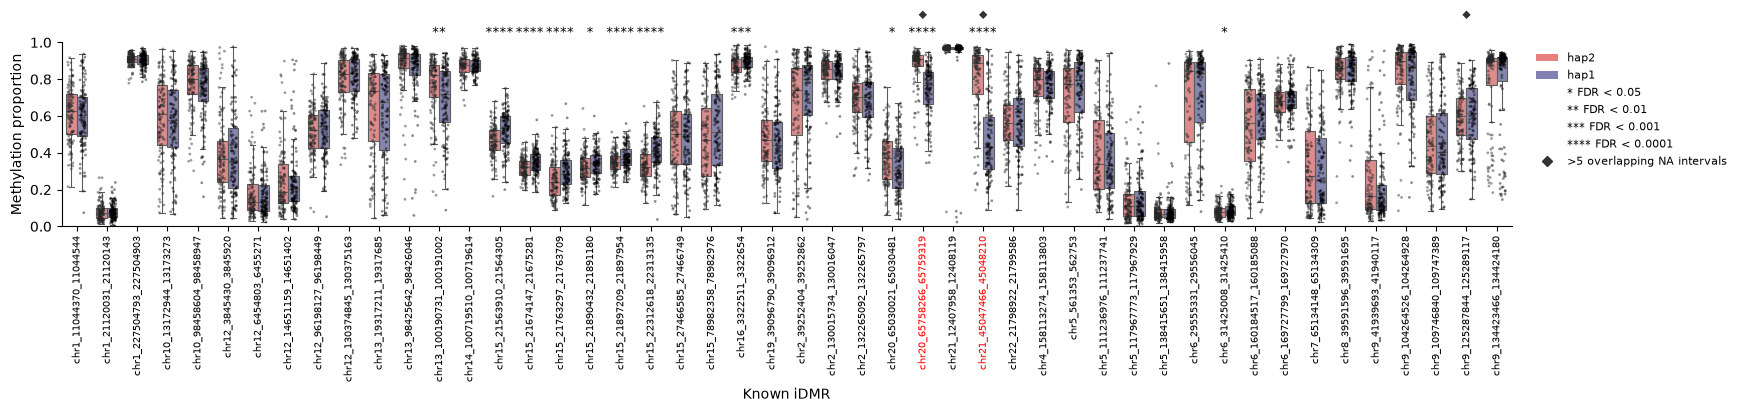

In [69]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ============================================================
# 0. Settings
# ============================================================

donor_col = "sample"
min_pairs = 3
na_threshold = 5

hap_order = ["hap2", "hap1"]

palette = {
    "hap2": "#e88080",
    "hap1": "#8080b3"
}

plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

os.makedirs(figureDir, exist_ok=True)

# ============================================================
# 1. Prepare data
# ============================================================

plot_df = missing_idmrs.copy()

plot_df["methylation"] = pd.to_numeric(
    plot_df["methylation"],
    errors="coerce"
)

plot_df["methylation"] = plot_df["methylation"].replace(
    [np.inf, -np.inf],
    np.nan
)

plot_df = plot_df.loc[
    plot_df["hap"].isin(hap_order)
].copy()

# Check duplicate observations
keys = ["id", donor_col, "hap"]

duplicates = plot_df.loc[
    plot_df.duplicated(keys, keep=False)
]

print("Duplicated observations:", len(duplicates))

if not duplicates.empty:
    print(duplicates.sort_values(keys).head(20))

    raise ValueError(
        "Duplicate (id, sample, hap) observations found. "
        "Resolve duplicates before performing paired tests."
    )

# ============================================================
# 2. Region-specific paired t-tests
# ============================================================

results = []

for region_id, sub in plot_df.groupby("id"):

    paired = (
        sub.pivot(
            index=donor_col,
            columns="hap",
            values="methylation"
        )
        .reindex(columns=hap_order)
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=hap_order)
    )

    n_pairs = len(paired)

    t_stat = np.nan
    p_value = np.nan
    mean_diff = np.nan
    status = "Insufficient pairs"

    if n_pairs > 0:
        differences = paired["hap2"] - paired["hap1"]
        mean_diff = differences.mean()

    if n_pairs >= min_pairs:

        # All paired differences are zero
        if differences.eq(0).all():
            t_stat = 0.0
            p_value = 1.0
            status = "All differences zero"

        # Constant nonzero differences
        elif np.isclose(
            differences.std(ddof=1),
            0,
            atol=1e-12,
            rtol=0
        ):
            status = "Zero variance"

        else:
            result = ttest_rel(
                paired["hap2"],
                paired["hap1"],
                alternative="two-sided"
            )

            t_stat = result.statistic
            p_value = result.pvalue
            status = "Success"

    results.append({
        "id": region_id,
        "n_pairs": n_pairs,
        "mean_diff_hap2_minus_hap1": mean_diff,
        "t_stat": t_stat,
        "p_value": p_value,
        "status": status
    })

ttest_results = pd.DataFrame(results)

# ============================================================
# 3. BH-FDR correction
# ============================================================

ttest_results["p_adj"] = np.nan

valid = np.isfinite(ttest_results["p_value"])

if valid.any():
    ttest_results.loc[valid, "p_adj"] = multipletests(
        ttest_results.loc[valid, "p_value"],
        method="fdr_bh"
    )[1]

print("\nPaired t-test results:")
print(ttest_results["status"].value_counts())

print(
    "\nSignificant regions (FDR < 0.05):",
    (ttest_results["p_adj"] < 0.05).sum()
)

# ============================================================
# 4. Count NA intervals overlapping missing iDMRs
# ============================================================

na_overlap_counts = (
    intersect_df_missing_na
    .assign(
        has_overlap=lambda x: x["chr_na"].ne(".")
    )
    .groupby("id")["has_overlap"]
    .sum()
    .reset_index(name="na_overlap_count")
)

ttest_results = ttest_results.merge(
    na_overlap_counts,
    on="id",
    how="left",
    validate="one_to_one"
)

ttest_results["na_overlap_count"] = (
    ttest_results["na_overlap_count"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# 5. Annotation preparation
# ============================================================

def significance_stars(p):
    if not np.isfinite(p):
        return ""
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""


order = plot_df["id"].dropna().unique().tolist()

p_map = ttest_results.set_index("id")["p_adj"]
count_map = ttest_results.set_index("id")["na_overlap_count"]

# Handle optional strong_evidence column
if "strong_evidence" in plot_df.columns:

    evidence_mask = (
        plot_df["strong_evidence"]
        .fillna(False)
        .eq(True)
    )

    highlighted_ticks = set(
        plot_df.loc[evidence_mask, "id"].astype(str)
    )

else:
    highlighted_ticks = set()

# ============================================================
# 6. Boxplot + stripplot
# ============================================================

fig, ax = plt.subplots(figsize=(20, 4))

sns.boxplot(
    data=plot_df,
    x="id",
    y="methylation",
    hue="hap",
    order=order,
    hue_order=hap_order,
    palette=palette,
    showfliers=False,
    linewidth=0.8,
    width=0.7,
    ax=ax
)

sns.stripplot(
    data=plot_df,
    x="id",
    y="methylation",
    hue="hap",
    order=order,
    hue_order=hap_order,
    dodge=True,
    jitter=0.2,
    color="black",
    size=2,
    alpha=0.45,
    ax=ax
)

# ============================================================
# 7. Significance and NA annotations
# ============================================================

for x, region_id in enumerate(order):

    stars = significance_stars(
        p_map.get(region_id, np.nan)
    )

    if stars:
        ax.text(
            x,
            1.02,
            stars,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=9,
            clip_on=False
        )

    if count_map.get(region_id, 0) > na_threshold:
        ax.text(
            x,
            1.12,
            "◆",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=8,
            color="#333333",
            clip_on=False
        )

# ============================================================
# 8. Formatting
# ============================================================

ax.set_xlabel("Known iDMR")
ax.set_ylabel("Methylation proportion")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=90,
    labelsize=7
)

for label in ax.get_xticklabels():
    if label.get_text() in highlighted_ticks:
        label.set_color("red")

legend_elements = [
    Patch(
        facecolor=palette["hap2"],
        label="hap2"
    ),
    Patch(
        facecolor=palette["hap1"],
        label="hap1"
    ),
    Line2D(
        [], [],
        linestyle="none",
        label="* FDR < 0.05"
    ),
    Line2D(
        [], [],
        linestyle="none",
        label="** FDR < 0.01"
    ),
    Line2D(
        [], [],
        linestyle="none",
        label="*** FDR < 0.001"
    ),
    Line2D(
        [], [],
        linestyle="none",
        label="**** FDR < 0.0001"
    ),
    Line2D(
        [], [],
        linestyle="none",
        marker="D",
        color="#333333",
        markersize=5,
        label=f">{na_threshold} overlapping NA intervals"
    )
]

ax.legend(
    handles=legend_elements,
    title="",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    fontsize=8
)

sns.despine()

fig.subplots_adjust(
    top=0.78,
    bottom=0.32,
    right=0.85
)

# ============================================================
# 9. Save results
# ============================================================

fig.savefig(
    os.path.join(
        figureDir,
        "boxplot_missing_idmr_methylation.pdf"
    ),
    dpi=600,
    bbox_inches="tight"
)

ttest_results.to_csv(
    os.path.join(
        figureDir,
        "missing_idmr_paired_ttest.tsv"
    ),
    sep="\t",
    index=False
)

plt.show()

In [71]:
results = []

for region_id, sub in missing_idmrs.groupby("id"):

    paired = (
        sub.pivot(
            index="sample",
            columns="hap",
            values="methylation"
        )
        .reindex(columns=hap_order)
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=hap_order)
    )

    n_pairs = len(paired)

    t_stat = np.nan
    p_value = np.nan
    mean_diff = np.nan
    status = "Insufficient pairs"

    if n_pairs > 0:
        differences = paired["hap2"] - paired["hap1"]
        mean_diff = differences.mean()

    if n_pairs >= min_pairs:

        if differences.eq(0).all():
            t_stat = 0.0
            p_value = 1.0
            status = "All differences zero"

        elif np.isclose(
            differences.std(ddof=1),
            0,
            atol=1e-12,
            rtol=0
        ):
            status = "Zero variance"

        else:
            result = ttest_rel(
                paired["hap2"],
                paired["hap1"],
                alternative="two-sided"
            )

            t_stat = result.statistic
            p_value = result.pvalue
            status = "Success"

    results.append({
        "id": region_id,
        "n_pairs": n_pairs,
        "mean_diff_hap2_minus_hap1": mean_diff,
        "t_stat": t_stat,
        "p_value": p_value,
        "status": status
    })

ttest_results = pd.DataFrame(results)

print(ttest_results["status"].value_counts())
display(ttest_results.head())

status
Success    48
Name: count, dtype: int64


,id,n_pairs,mean_diff_hap2_minus_hap1,t_stat,p_value,status
0,chr10_13172944_13173273,123,0.015126,0.555578,0.579517,Success
1,chr10_98458604_98458947,123,0.033075,1.798053,0.074642,Success
2,chr12_130374845_130375163,122,-0.018941,-1.178041,0.241092,Success
3,chr12_14651159_14651402,122,-0.002654,-0.127878,0.898458,Success
4,chr12_3845430_3845920,122,-0.002833,-0.102211,0.918758,Success


In [72]:
ttest_results["p_adj"] = np.nan

valid = np.isfinite(ttest_results["p_value"])

if valid.any():
    ttest_results.loc[valid, "p_adj"] = multipletests(
        ttest_results.loc[valid, "p_value"],
        method="fdr_bh"
    )[1]

ttest_results = ttest_results.merge(
    na_overlap_counts,
    on="id",
    how="left",
    validate="one_to_one"
)

ttest_results["na_overlap_count"] = (
    ttest_results["na_overlap_count"]
    .fillna(0)
    .astype(int)
)

print("FDR < 0.05:", (ttest_results["p_adj"] < 0.05).sum())
print("FDR < 1e-5:", (ttest_results["p_adj"] < 1e-5).sum())
print("FDR < 1e-10:", (ttest_results["p_adj"] < 1e-10).sum())

display(ttest_results.head())

FDR < 0.05: 12
FDR < 1e-5: 5
FDR < 1e-10: 3


,id,n_pairs,mean_diff_hap2_minus_hap1,t_stat,p_value,status,p_adj,na_overlap_count
0,chr10_13172944_13173273,123,0.015126,0.555578,0.579517,Success,0.772689,0
1,chr10_98458604_98458947,123,0.033075,1.798053,0.074642,Success,0.210753,0
2,chr12_130374845_130375163,122,-0.018941,-1.178041,0.241092,Success,0.445093,0
3,chr12_14651159_14651402,122,-0.002654,-0.127878,0.898458,Success,0.992958,0
4,chr12_3845430_3845920,122,-0.002833,-0.102211,0.918758,Success,0.992958,0


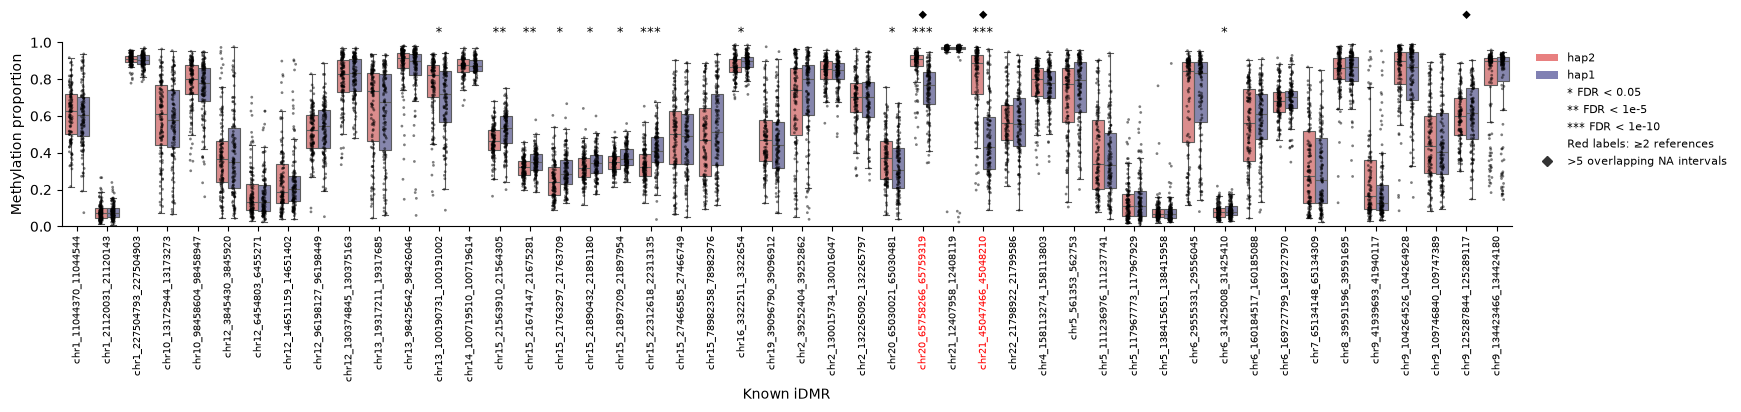

In [73]:
def significance_stars(p):
    if not np.isfinite(p):
        return ""
    if p < 1e-10:
        return "***"
    if p < 1e-5:
        return "**"
    if p < 0.05:
        return "*"
    return ""


order = missing_idmrs["id"].dropna().unique().tolist()

p_map = ttest_results.set_index("id")["p_adj"]
na_map = ttest_results.set_index("id")["na_overlap_count"]

highlighted_ticks = set(
    missing_idmrs.loc[
        missing_idmrs["strong_evidence"].fillna(False),
        "id"
    ].astype(str)
)

fig, ax = plt.subplots(figsize=(20, 4))

sns.boxplot(
    data=missing_idmrs,
    x="id",
    y="methylation",
    hue="hap",
    order=order,
    hue_order=hap_order,
    palette=palette,
    showfliers=False,
    linewidth=0.8,
    ax=ax
)

sns.stripplot(
    data=missing_idmrs,
    x="id",
    y="methylation",
    hue="hap",
    order=order,
    hue_order=hap_order,
    dodge=True,
    palette={"hap1": "black", "hap2": "black"},
    size=2,
    alpha=0.5,
    ax=ax
)

for x, region_id in enumerate(order):

    stars = significance_stars(
        p_map.get(region_id, np.nan)
    )

    if stars:
        ax.text(
            x, 1.02, stars,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=9,
            clip_on=False
        )

    if na_map.get(region_id, 0) > 5:
        ax.text(
            x, 1.12, "◆",
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=8,
            clip_on=False
        )

ax.set_xlabel("Known iDMR")
ax.set_ylabel("Methylation proportion")
ax.set_ylim(0, 1)

ax.tick_params(axis="x", rotation=90, labelsize=7)

for label in ax.get_xticklabels():
    if label.get_text() in highlighted_ticks:
        label.set_color("red")

legend_elements = [
    Patch(facecolor=palette["hap2"], label="hap2"),
    Patch(facecolor=palette["hap1"], label="hap1"),
    Line2D([], [], linestyle="none", label="* FDR < 0.05"),
    Line2D([], [], linestyle="none", label="** FDR < 1e-5"),
    Line2D([], [], linestyle="none", label="*** FDR < 1e-10"),
    Line2D([], [], linestyle="none", label="Red labels: ≥2 references"),
    Line2D([], [], linestyle="none", marker="D",
           color="#333333", markersize=5,
           label=">5 overlapping NA intervals")
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=8
)

sns.despine()
fig.subplots_adjust(top=0.78, bottom=0.32, right=0.85)

fig.savefig(
    os.path.join(figureDir, "boxplot_missing_idmr_methylation.pdf"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [74]:
ttest_results.to_csv(
    os.path.join(figureDir, "missing_idmr_paired_ttest.tsv"),
    sep="\t",
    index=False
)

missing_idmrs.to_csv(
    os.path.join(figureDir, "missing_idmr_methylation.tsv"),
    sep="\t",
    index=False
)

print("Total missing known iDMRs:", missing_df["id"].nunique())
print("Missing iDMRs with methylation:", missing_idmrs["id"].nunique())
print("Regions tested:", ttest_results["p_value"].notna().sum())
print("Significant (FDR < 0.05):", (ttest_results["p_adj"] < 0.05).sum())

print(
    "Strong-evidence regions:",
    missing_idmrs.loc[
        missing_idmrs["strong_evidence"], "id"
    ].nunique()
)

print(
    "Regions with >5 NA overlaps:",
    (ttest_results["na_overlap_count"] > 5).sum()
)

Total missing known iDMRs: 48
Missing iDMRs with methylation: 48
Regions tested: 48
Significant (FDR < 0.05): 12
Strong-evidence regions: 2
Regions with >5 NA overlaps: 3


num_of_ref   1   2   3   4   5
cat                           
Matched     54  27  14  13  29
Missing     46   2   0   0   0
Mixed_Sign   0   2   2   1   3


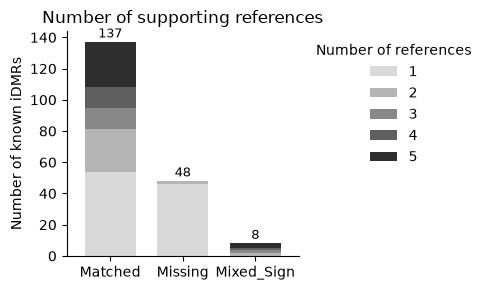

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. Count references for each known iDMR
# ============================================================

ref_df = known_summary.copy()

def count_references(ref):
    if pd.isna(ref):
        return 0

    refs = {
        r.strip()
        for r in str(ref).split(",")
        if r.strip() not in ["", ".", "nan"]
    }

    return len(refs)

ref_df["num_of_ref"] = ref_df["reference"].apply(count_references)

# ============================================================
# 2. Count known iDMRs by category and reference number
# ============================================================

pivot_df = pd.crosstab(
    ref_df["cat"],
    ref_df["num_of_ref"]
)

cat_order = ["Matched", "Missing", "Mixed_Sign"]
ref_order = [1, 2, 3, 4, 5]

pivot_df = pivot_df.reindex(
    index=cat_order,
    columns=ref_order,
    fill_value=0
)

# Check if any reference counts are excluded
excluded = ref_df.loc[~ref_df["num_of_ref"].isin(ref_order)]

if not excluded.empty:
    print(
        f"Warning: {len(excluded)} known iDMRs have "
        "0 or more than 5 references and are not shown."
    )

print(pivot_df)

# ============================================================
# 3. Stacked barplot
# ============================================================

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

colors = plt.cm.Greys(
    np.linspace(0.25, 0.85, len(ref_order))
)

fig, ax = plt.subplots(figsize=(5, 3))

pivot_df.plot(
    kind="bar",
    stacked=True,
    color=colors,
    width=0.7,
    ax=ax
)

ax.set_xlabel("")
ax.set_ylabel("Number of known iDMRs")
ax.set_title("Number of supporting references")

ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Number of references",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

# Add total count above each bar
for i, total in enumerate(pivot_df.sum(axis=1)):
    ax.text(
        i,
        total + 1,
        str(int(total)),
        ha="center",
        va="bottom",
        fontsize=9
    )

sns.despine()
plt.tight_layout()

fig.savefig(
    os.path.join(figureDir, "reference_number.pdf"),
    bbox_inches="tight"
)

plt.show()